# Comparativa de Funciones de Activación y Métodos de Gradiente en MLP

Este notebook interactivo ha sido diseñado como recurso didáctico para la materia Sistemas de Inteligencia Artificial. El objetivo es analizar de manera práctica y visual cómo afectan las diferentes **funciones de activación** y los distintos **métodos de gradiente descendente** al entrenamiento de un Perceptrón Multicapa (MLP).

## Objetivos de la actividad:
1. **Comparar funciones de activación** (Sigmoide, Tangente Hiperbólica y ReLU) en la capa oculta de una red neuronal.
2. **Comparar variantes del Descenso de Gradiente**:
   * **Gradiente Descendente Clásico (GD o Batch GD)**: Actualización con todo el conjunto de datos.
   * **Gradiente Descendente Estocástico (SGD)**: Actualización muestra por muestra.
   * **Gradiente Descendente por Mini-batches**: Actualización por bloques o subconjuntos.
3. **Problema No Lineal (Circular)**: Clasificar puntos dentro y fuera de un círculo, superando la limitación de problemas lineales sin recurrir al ejercicio XOR ya visto.

## Paso 1: Importación de librerías y generación del dataset circular
Generamos una distribución bidimensional donde la Clase 1 está dentro de un círculo de radio $r = 1.0$ y la Clase 0 está fuera. Esto representa un reto de clasificación no lineal.

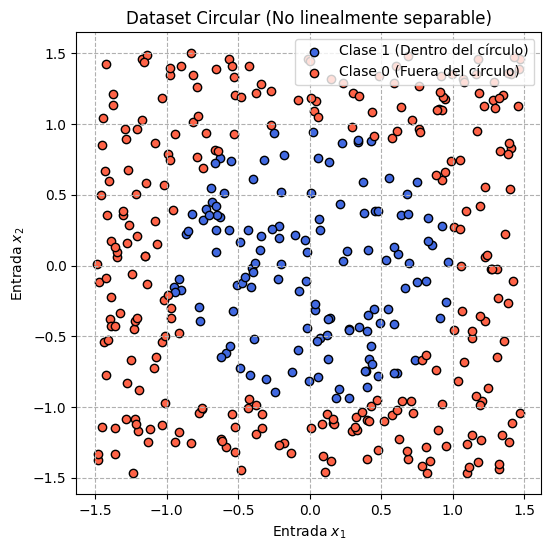

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fijamos la semilla para reproducibilidad
np.random.seed(42)

def generar_datos_circular(n_muestras=400):
    # Generar puntos uniformes en el rango [-1.5, 1.5] para x1 y x2
    X = np.random.uniform(-1.5, 1.5, (2, n_muestras))
    # Clase 1 si está dentro del círculo de radio 1.0, Clase 0 de lo contrario
    distancias = np.sqrt(X[0]**2 + X[1]**2)
    d = (distancias < 1.0).astype(int).reshape(1, -1)
    return X, d

X, d = generar_datos_circular(400)

# Graficar el dataset
plt.figure(figsize=(6, 6))
plt.scatter(X[0, d[0] == 1], X[1, d[0] == 1], c='royalblue', edgecolors='k', label='Clase 1 (Dentro del círculo)')
plt.scatter(X[0, d[0] == 0], X[1, d[0] == 0], c='tomato', edgecolors='k', label='Clase 0 (Fuera del círculo)')
plt.title("Dataset Circular (No linealmente separable)")
plt.xlabel("Entrada $x_1$")
plt.ylabel("Entrada $x_2$")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--')
plt.show()

## Paso 2: Funciones de Activación y sus Derivadas
Para realizar la propagación hacia atrás (Backpropagation), necesitamos programar la derivada de cada función.
Nota que las derivadas se calculan usando el valor de activación ya obtenido $a = f(z)$ por eficiencia computacional.

In [ ]:
# 1. Función Sigmoide
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_deriv(a):
    # Entrada 'a' es la salida de la neurona: a = sigmoid(z)
    return a * (1 - a)

# 2. Función Tangente Hiperbólica (Tanh)
def tanh(z):
    return np.tanh(z)

def tanh_deriv(a):
    # Entrada 'a' es la salida de la neurona: a = tanh(z)
    return 1 - a**2

# 3. Función ReLU (Rectified Linear Unit)
def relu(z):
    return np.maximum(0, z)

def relu_deriv(a):
    # Para ReLU, si la activación es mayor que 0, la derivada es 1; si es <= 0, es 0
    return (a > 0).astype(float)

## Paso 3: Definición del Perceptrón Multicapa (MLP) Modular
Creamos una función genérica que implementa el entrenamiento de un MLP de una capa oculta con $N$ neuronas ocultas. Permite parametrizar la activación oculta y la estrategia de descenso de gradiente.

In [ ]:
def inicializar_parametros(n_in=2, n_h=6, n_out=1):
    # Inicialización de Xavier para pesos, ceros para sesgos
    W1 = np.random.randn(n_h, n_in) * np.sqrt(2.0 / (n_in + n_h))
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_out, n_h) * np.sqrt(2.0 / (n_h + n_out))
    b2 = np.zeros((n_out, 1))
    return W1, b1, W2, b2

def entrenar_mlp(X, d, activacion="sigmoid", metodo="gd", lr=0.1, epochs=1000, batch_size=32):
    # Configurar función de activación elegida para la capa oculta
    if activacion == "sigmoid":
        func, func_deriv = sigmoid, sigmoid_deriv
    elif activacion == "tanh":
        func, func_deriv = tanh, tanh_deriv
    elif activacion == "relu":
        func, func_deriv = relu, relu_deriv
    else:
        raise ValueError("Función de activación no soportada")

    W1, b1, W2, b2 = inicializar_parametros(n_in=2, n_h=6, n_out=1)
    n_muestras = X.shape[1]
    historial_error = []

    for epoch in range(epochs):
        # Mezclar datos en cada época para SGD y Mini-batch
        indices = np.random.permutation(n_muestras)
        X_sh = X[:, indices]
        d_sh = d[:, indices]

        # Dividir según el método de gradiente seleccionado
        if metodo == "gd":
            batches_X = [X]
            batches_d = [d]
        elif metodo == "sgd":
            batches_X = [X_sh[:, i:i+1] for i in range(n_muestras)]
            batches_d = [d_sh[:, i:i+1] for i in range(n_muestras)]
        elif metodo == "minibatch":
            batches_X = [X_sh[:, i:i+batch_size] for i in range(0, n_muestras, batch_size)]
            batches_d = [d_sh[:, i:i+batch_size] for i in range(0, n_muestras, batch_size)]
        else:
            raise ValueError("Método de gradiente no válido")

        error_acumulado = 0.0

        for xb, db in zip(batches_X, batches_d):
            m_lote = xb.shape[1]  # Número de elementos en este lote

            # 1. Forward Pass (Propagación hacia adelante)
            z1 = np.dot(W1, xb) + b1
            a1 = func(z1)  # Activación de la capa oculta
            z2 = np.dot(W2, a1) + b2
            a2 = sigmoid(z2)  # Activación de salida (Sigmoide para clasificación binaria)

            # 2. Cálculo del Error
            error = db - a2
            error_acumulado += np.sum(np.abs(error))

            # 3. Backward Pass (Retropropagación del gradiente)
            # Error en capa de salida
            da2 = error * sigmoid_deriv(a2)
            dz2 = da2

            # Error en capa oculta
            da1 = np.dot(W2.T, dz2)
            dz1 = da1 * func_deriv(a1)

            # 4. Actualización de Pesos y Sesgos
            # Normalizamos los gradientes dividiendo por el tamaño del lote
            W2 += lr * np.dot(dz2, a1.T) / m_lote
            b2 += lr * np.sum(dz2, axis=1, keepdims=True) / m_lote

            W1 += lr * np.dot(dz1, xb.T) / m_lote
            b1 += lr * np.sum(dz1, axis=1, keepdims=True) / m_lote

        # Guardar el error medio absoluto de la época actual
        historial_error.append(error_acumulado / n_muestras)

    return W1, b1, W2, b2, historial_error

## Experimento 1: Comparando Funciones de Activación
Entrenamos la red usando el método clásico de Gradiente Descendente (GD) con tres funciones de activación diferentes: **Sigmoide, Tanh y ReLU** en la capa oculta. Observamos el comportamiento del error.

Entrenando MLP con activación: Sigmoide...
Entrenando MLP con activación: Tanh...
Entrenando MLP con activación: ReLU...


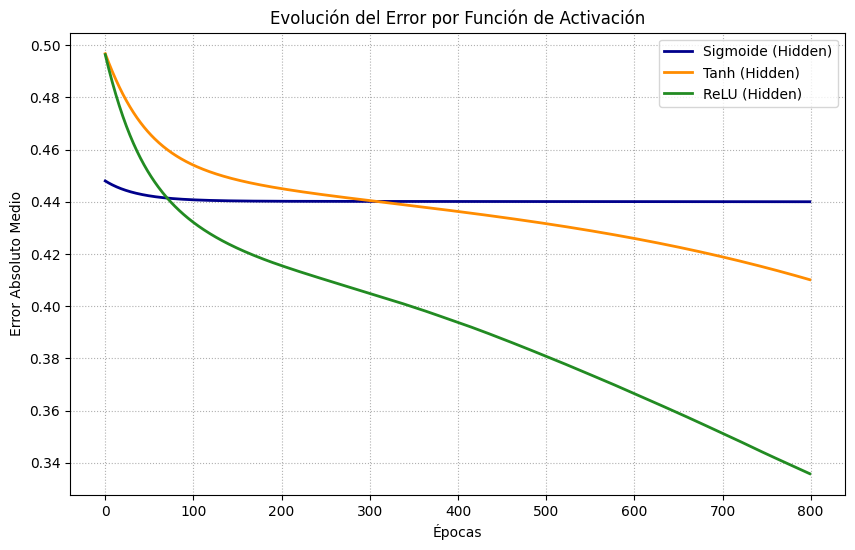

In [ ]:
epochs = 800
lr = 0.2

print("Entrenando MLP con activación: Sigmoide...")
_, _, _, _, err_sig = entrenar_mlp(X, d, activacion="sigmoid", metodo="gd", lr=lr, epochs=epochs)

print("Entrenando MLP con activación: Tanh...")
_, _, _, _, err_tanh = entrenar_mlp(X, d, activacion="tanh", metodo="gd", lr=lr, epochs=epochs)

print("Entrenando MLP con activación: ReLU...")
_, _, _, _, err_relu = entrenar_mlp(X, d, activacion="relu", metodo="gd", lr=lr, epochs=epochs)

plt.figure(figsize=(10, 6))
plt.plot(err_sig, label="Sigmoide (Hidden)", color="darkblue", linewidth=2)
plt.plot(err_tanh, label="Tanh (Hidden)", color="darkorange", linewidth=2)
plt.plot(err_relu, label="ReLU (Hidden)", color="forestgreen", linewidth=2)
plt.title("Evolución del Error por Función de Activación")
plt.xlabel("Épocas")
plt.ylabel("Error Absoluto Medio")
plt.legend()
plt.grid(True, linestyle=':')
plt.show()

## Experimento 2: Comparando Métodos de Gradiente
Ahora, fijamos la activación de la capa oculta como **Tanh** y comparamos el desempeño de las tres variantes de descenso de gradiente:
1. **GD (Batch GD)**: Actualización una vez por época, usando todo el dataset.
2. **SGD (Estocástico)**: Actualización muestra por muestra en orden aleatorio.
3. **Mini-batch GD**: Actualización usando bloques de tamaño intermedio (por ejemplo, lotes de 16 muestras).

Entrenando con Gradiente Descendente Clásico (GD)...
Entrenando con Gradiente Descendente Estocástico (SGD)...
Entrenando con Mini-batch GD...


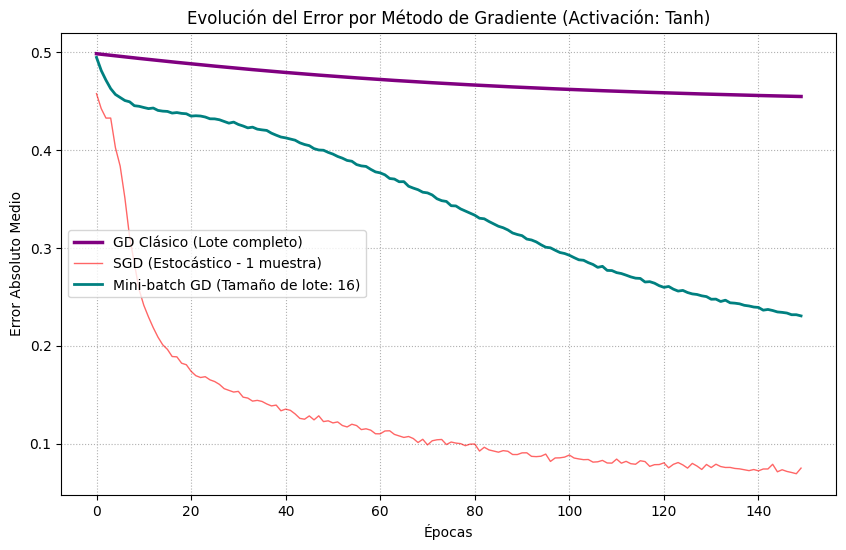

In [ ]:
epochs_metodos = 150
lr_metodos = 0.15

print("Entrenando con Gradiente Descendente Clásico (GD)...")
_, _, _, _, err_gd = entrenar_mlp(X, d, activacion="tanh", metodo="gd", lr=lr_metodos, epochs=epochs_metodos)

print("Entrenando con Gradiente Descendente Estocástico (SGD)...")
_, _, _, _, err_sgd = entrenar_mlp(X, d, activacion="tanh", metodo="sgd", lr=lr_metodos, epochs=epochs_metodos)

print("Entrenando con Mini-batch GD...")
_, _, _, _, err_mb = entrenar_mlp(X, d, activacion="tanh", metodo="minibatch", lr=lr_metodos, epochs=epochs_metodos, batch_size=16)

plt.figure(figsize=(10, 6))
plt.plot(err_gd, label="GD Clásico (Lote completo)", color="purple", linewidth=2.5)
plt.plot(err_sgd, label="SGD (Estocástico - 1 muestra)", color="red", alpha=0.6, linewidth=1)
plt.plot(err_mb, label="Mini-batch GD (Tamaño de lote: 16)", color="teal", linewidth=2)
plt.title("Evolución del Error por Método de Gradiente (Activación: Tanh)")
plt.xlabel("Épocas")
plt.ylabel("Error Absoluto Medio")
plt.legend()
plt.grid(True, linestyle=':')
plt.show()

## Guía de Análisis y Preguntas para la Clase
A partir de las gráficas resultantes de los dos experimentos, responde las siguientes preguntas:

1. **Sobre las funciones de activación (Experimento 1)**:
   * ¿Cuál de las funciones de activación (Sigmoide, Tanh, ReLU) logró reducir el error promedio de manera más acelerada?
   * ¿Por qué crees que la función Sigmoide suele converger de forma más lenta que las otras opciones?

2. **Sobre los métodos de optimización (Experimento 2)**:
   * ¿Cómo describirías la "estabilidad" o nivel de ruido en la curva de aprendizaje de SGD comparado con el GD clásico?
   * ¿A qué se debe el comportamiento tan oscilatorio de SGD y qué beneficios o perjuicios prácticos aporta esta oscilación?
   * ¿Por qué el método Mini-batch se considera un excelente balance de eficiencia y convergencia en redes de gran escala?